# Counting the Kernza stems in a single photograph

**A guided tour, one step at a time.**

This Jupyter notebook uses one photograph, of a single Kernza sample, and walks you through
the process of counting the number of stems in that photo. 


### You do not need to know how to code

You do not need to know any Python, or anything about programming, to understand this tutorial -- we will walk you through every step. This notebook contains sections of *text* and *cells*. You are currently reading a section of text -- an explanation of what's going on in the notebook, written in plain English, in plain Arial font. 

Underneath the header below that says "**Step 1 - Your set up**" there is a gray box. This is a *cell*.  Cells contain code, in font kind of like a `typewriter font`. You run the code by clicking on the cell, and then hitting **Shift + Enter**. Running the cell causes the code that cell contains to execute. Later cells depend on earlier ones, so make sure to run the cells **in order** as you go through the tutorial.

After a cell has run through successfully, **output** will appear *beneath* the cell. It will not be in the the cell itself, but it will appear in the same font as the code within the cells. This output will give you information relevant to the code that has just run.

### Overview of the tutorial steps (probably remove this altogether)

1. open a photo of some stems, and the bounding boxes boxes a person drew on it,
2. cut the photo into small tiles,
3. look at those tiles, with the hand-drawn boxes on them,
4. build the trained model and load it,
5. find stems in every tile,
6. put the tiles back together into one count,
7. compare what the person marked with what the model found.

**How long it takes:** about two minutes of setup, then a few seconds per step,
except step 6 which takes roughly 10–15 seconds without a graphics card.

---
## Step 1 — Your set up

This is the only code you may need to modify. After this step, you should read through all of the text and output as you go through the tutorial, but you should not modify the code in the cells.

### File locations
The `Set file directories` section of the cell below tells the code where on your computer to find the extra files it needs. These extra files are the **data**, i.e. the Kernza photos, and the **weights**, i.e. the numbers that make up the trained model which will count the stems.

If you've downloaded our sample folder from Zenodo, that folder is already set up to work with this tutorial. The photos that compose our test set are already downloaded, and you can use them to go through the tutorial. We recommend doing this for at least your first run through the tutorial, to ensure everything runs properly on your machine, before using your own photos. The first section of the cell below sets the working directory to the appropriate folder within that folder structure. (See below for an explanation of working directory.) 

If you would like to use your own photos, type the path of the folder that contains those photos next to `DATA_DIR =` in the cell below. When you first download this file, that line will read `DATA_DIR     = "../Dataset/Data_KZ_stems/test"`. You will replace `../Dataset/Data_KZ_stems/test` with your own file path. The file path **must** be in quotation marks. 
**Note** that much of this tutorial is designed to use an **annotation file** in addition to photos, to enable comparison between manual annotations and model-generated bounding boxes. If you do not have manually annotated images, you should use the test photos and annotations we have provided.

The `WEIGHTS_PATH` is already set to find the weights file within the folder structure you have downloaded from Zenodo. You should not need to change this, unless you have modified where different files are saved within the folder.

### Cell output
Once the `DATA_DIR` and `WEIGHTS_PATH` are set, run the cell by clicking within the cell and hitting Ctrl-Enter. The code will check that the folders and files exist. If they do, the output text "Found the photo folder and model file" will appear directly beneath the cell, and you can move on to the next step. 

If there is an error, a red box will appear beneath the cell with some code in it. Look towards the bottom of that red box, where it says FileNotFoundError in red. (The top of the box may also say FileNotFoundError -- you can ignore the one at the top, and just look at the one towards the bottom of the box!) If the text that appears beneath the cell says that the photo folder and/or model file could not be found, check that there are no typos in the file paths, and double-check that both paths exist on your computer at the location you specified.

#### Working directory
If there is an error in finding the file paths, the output will tell you your current working directory. This is the location within your files that the code takes as its "home base," that is, the location that other file paths in the code are relative to. Let's say I (on a Windows computer) downloaded the whole folder from Zenodo and saved it in my Documents folder under the name `KernzaStemCountingTutorials`. The folder contains the subfolder with this Jupyter notebook, the subfolder with the model weights, and the subfolder with the the demo images, as well as a couple of other things. When I open this Jupyter notebook from its subfolder, which is called `OneImage`, my working directory will be:
`C:\Users\linne\Documents\KernzaStemCountingTutorials\OneImage`.

So when I tell the code to look for a file, it will look in the `OneImage` folder. The subfolder containing the images is called `Dataset\Data_KZ_Stems`, and is not in the `OneImage` folder. If we set `DATA_DIR = "Dataset\Data_KZ_Stems"`, it will cause a FileNotFoundError. `OneImage` and `Dataset\Data_KZ_Stems` are both subfolders contained in the `KernzaStemCountingTutorials` folder. To tell the code to look in the `KernzaStemCountingTutorials` folder, instead of in the `OneImage` subfolder, we type `..\` at the start of the file path -- this tells the code to look "up a level" in the file directory. From there, we can tell the code to look in the `Dataset\Data_KZ_stems` subfolder.

It's important to remember to specify file and folder paths (i.e. `DATA_DIR` and `WEIGHTS_PATH`) *relative to the working directory.* This is the only way the computer will be able to find them. 


In [2]:
#################################################################
### Set working directory (You don't need to edit this part!) ###
#################################################################

import os, sys
# Jupyter starts in the folder the notebook itself lives in, which is one level
# below the project's top folder. Step up, so that short paths like
# "data/test" mean what you would expect.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

###############################################################
### Set file directories (you MAY need to edit this part!)  ###
###############################################################

# Path for photos and the annotation file:
DATA_DIR     = "../Dataset/Data_KZ_stems/test"

# Path to the file for the trained model:
WEIGHTS_PATH = "../Trained_Model/yolo26_kernza_fr80000_ep1250000_lr10_box90000_cls5000_dfl11000_best.pt"

###########################################################################
### Double check the file locations (You don't need to edit this part!) ###
###########################################################################

# ----------------------------------------------------------------------------
# A quick check that these paths really exist, so that a typo is caught here
# rather than five cells later.

if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(
        f"Could not find DATA_DIR i.e. the folder containing the photos.\n"
        f"Current working directory: {os.getcwd()}\n"
        f"DATA_DIR is currently set to: {DATA_DIR}\n"
        f"Check for typos!"
    )

if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError(
        f"Could not find WEIGHTS_PATH i.e. the file containing the model weights.\n"
        f"Current working directory: {os.getcwd()}\n"
        f"WEIGHTS_PATH is currently set to: {WEIGHTS_PATH}\n"
        f"Check for typos!"
    )

if os.path.exists(WEIGHTS_PATH) and os.path.exists(DATA_DIR):
    print("Found the photo folder and the model file.")

Found the photo folder and the model file.


### Detection settings

These are some numerical settings that the model uses to determine what to count as a stem. They are explained in detail in the paper. (MANDAR: is this true?) They are set here to the values we used in the paper. You can change them if you'd like to see how changing these parameters affects stem detection. We recommend going through the tutorial the first time without changing them -- you can always come back and run through it again with different settings later.

`CONFIDENCE` is the confidence level the model requires to count something it's detected as a stem. Our value was 0.56.

`NMS_IOU` is the degree to which two boxes may overlap before they are considered to be a single stem. Our value was 0.50. (MANDAR: what does this mean?)

`PATCH_SIZE` is the size of the tiles each photo will be subdivided into, in pixels. This will be explained in more detail below, and is also explained in the paper. Our value was 640.

`OVERLAP` is the percent to which neighboring tiles will overlap, i.e., how much area one tile shares with its neighboring tile. This will also be explained in more detail below. Our value was 0.50, or 50%.

In [3]:
CONFIDENCE = 0.56    # how sure the model must be before we count something as a stem
NMS_IOU    = 0.50    # how much two boxes may overlap before we call them one stem
PATCH_SIZE = 640     # the size of the square tiles, in pixels
OVERLAP    = 0.50    # how much perimeter neighbouring tiles share along one side (0.50 = half a tile)


### Graphing settings

These settings control which photo you look at, and the colors used in the illustrative images below. On your first run through, you do not need to change these settings.

`IMAGE_INDEX` determines the photo you will look at over the course of this tutorial. In Python, counting starts at 0 instead of at 1, so `IMAGE_INDEX = 0` tells the tutorial to look at the first image in the folder, `IMAGE_INDEX = 1` will show the second image in the folder, etc. 

The images we generate over the course of the tutorial will have three different types of boxes drawn onto them, to illustrate what the code and model are doing. Below you can choose the colors of these three boxes. This is purely an aesthetic choice and does not affect any quantitative aspect of the code.

`COLOR_TRUTH` will be the color of the bounding boxes drawn by a person, also called manual annotations.
`COLOR_PREDICTION` will be the color of bounding boxes drawn by the model.
`COLOR_TILE` will be the color of the tiles the image will be subdivided into.

In [4]:
# --- Which photo to look at (0 = the first one) ---
IMAGE_INDEX = 0


# --- Colours, used consistently in every picture below ---
COLOR_TRUTH      = "#AE00FF"   # purple: a box a person drew
COLOR_PREDICTION = "#FFD400"   # yellow: a box the model found
COLOR_TILE       = "#E34948"   # red:    the outline of a tile

## Step 2 - Computer set up

From this point onwards, you should not modify any of the code in the cells.

This cell installs the Python packages the notebook needs to be able to run. It prints a lot of text -- this is normal! Wait for the output below the cell that reads "Setup finished." Below that, it will also print your current working directory (explained above, in step 1) and list the files and folders contained in the directory.

In [5]:
import os, sys

# Install the packages, at the versions this project is tested with.
REQUIREMENTS = "requirements.txt"
if os.path.exists(REQUIREMENTS):
    print("Installing from", REQUIREMENTS)
    %pip install --quiet -r $REQUIREMENTS
else:
    print(f"{REQUIREMENTS} not found, installing current versions instead.")
    %pip install --quiet ultralytics zxing-cpp matplotlib pandas tqdm ipywidgets

print("\nSetup finished.")
print("Working folder:", os.getcwd())
print("What is in it:", ", ".join(sorted(os.listdir())[:12]) or "(nothing)")

requirements.txt not found, installing current versions instead.
Note: you may need to restart the kernel to use updated packages.

Setup finished.
Working folder: C:\Users\linne\Documents\Work\Selbstständig\GRIM_STIM\01_Code\Tutorials\OneImage
What is in it: .ipynb_checkpoints, LinneaRunthrough_Tutorial_visualizing_inference_for_one_image.ipynb, SingleImageTutorial.ipynb, Tutorial_visualizing_inference_for_one_image.ipynb


This following cell checks whether your computer has a graphics card or not. If you have a GPU, it will use that GPU. If you do not have a GPU (which is not a problem), it will use your computer's CPU. The output beneath the cell says whether the tutorial will use a GPU or a CPU.

In [6]:
import inspect, json, os, time

import numpy as np                      # arrays of numbers
from PIL import Image, ImageOps         # opening and rotating photos

import matplotlib.pyplot as plt         # drawing pictures
import matplotlib.patches as mpatches   # drawing rectangles on those pictures

import torch                            # the maths engine the model runs on
import torch.nn as nn
import torchvision
from ultralytics import YOLO            # the family of models we start from

# Use a graphics card if this computer has one, otherwise use the ordinary CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Running on:", DEVICE)
if DEVICE.type == "cpu":
    print("No graphics card was found, so the CPU will do the work. That is")
    print("perfectly fine - expect roughly 10-15 seconds per photo instead of about 1.")
else:
    print("Graphics card:", torch.cuda.get_device_name(0))

Running on: cpu
No graphics card was found, so the CPU will do the work. That is
perfectly fine - expect roughly 10-15 seconds per photo instead of about 1.


In [7]:
# ============================================================================
#  SETTINGS
# ============================================================================

# --- Where things are ---
DATA_DIR     = "../Dataset/Data_KZ_stems/test"                            # photos + the annotation file
WEIGHTS_PATH = "../Trained_Model/yolo26_kernza_fr80000_ep1250000_lr10_box90000_cls5000_dfl11000_best.pt" # the trained model

# --- Which photo to look at (0 = the first one) ---
IMAGE_INDEX = 0

# --- Detection settings: these reproduce the paper ---
CONFIDENCE = 0.56    # how sure the model must be before we count something
NMS_IOU    = 0.50    # how much two boxes may overlap before we call them one stem
PATCH_SIZE = 640     # the size of the square tiles, in pixels
OVERLAP    = 0.50    # how much neighbouring tiles share (0.50 = half a tile)

# --- Colours, used consistently in every picture below ---
COLOR_TRUTH      = "#AE00FF"   # purple: a box a person drew
COLOR_PREDICTION = "#FFD400"   # yellow: a box the model found
COLOR_TILE       = "#E34948"   # red:    the outline of a tile

# ----------------------------------------------------------------------------
# A quick check that these paths really exist, so that a typo is caught here
# rather than five cells later.
for path in (DATA_DIR, WEIGHTS_PATH):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Could not find: {path}\n"
            f"This notebook is looking inside: {os.getcwd()}\n"
            "If that folder ends in 'notebooks', run the setup cell above again.\n"
            "Otherwise the paths in this cell need correcting."
        )

print("Found the photo folder and the model file. Settings loaded.")

Found the photo folder and the model file. Settings loaded.


---
## Step 2 — Open the annotations

Somebody sat down and drew a box around every stem in every photo. A box drawn around a stem is called a "bounding box" or a "bbox". These boxes can be drawn by hand as just described, a.k.a. "manual" annotations. Bounding boxes are also generated by the model, which is how the model counts stems. These modelled bounding boxes will be generated below. We'll load the manual bounding boxes in the cell below, to take a look and to have something to check our model predictions against later.

All of the manual bounding boxes, for all of the photos in our dataset folder, are saved in a single file called `_annotations.coco.json`. 

The cell below loads this file, and outputs some basic information about it. The output also lists the filenames included in the data folder, along with their indexes - i.e., the number you could use up in Step 1 to set `IMAGE_INDEX` to the file you want to look at.

### A quick overview of the annotations file (optional)

"COCO" is just the name of the layout the file uses; it is the most common way of storing information about bounding boxes.

The COCO file has two lists that matter:

| list | what it holds |
|---|---|
| `images` | one entry per photo: its `id` and its `file_name` |
| `annotations` | one entry per **bounding box**: which photo it belongs to (`image_id`) and where it's located in the photo (`bbox`) |

A `bbox` is four numbers: `[left, top, width, height]`, measured in pixels from
the **top-left** corner of the photo. Note that it is a corner plus a size, not
two corners — later on the model will report boxes the other way round, and
mixing the two up is the most common mistake in this kind of work.

In [8]:
json_path = os.path.join(DATA_DIR, "_annotations.coco.json")

with open(json_path, "r") as f:
    coco = json.load(f)

print(f"This file describes {len(coco['images'])} photos "
      f"and {len(coco['annotations'])} hand-drawn boxes in total.")
print()
print("The first few photos, with the index you would put in IMAGE_INDEX:")
for i, entry in enumerate(coco["images"][:8]):
    print(f"   {i:>3}   {entry['file_name']}")
if len(coco["images"]) > 8:
    print(f"   ...   and {len(coco['images']) - 8} more")

This file describes 50 photos and 6748 hand-drawn boxes in total.

The first few photos, with the index you would put in IMAGE_INDEX:
     0   231_jpg.rf.6RwoGPxtUKSssbzTgXo0.jpg
     1   233_jpg.rf.JwTamPLhKCMDtfvQ6FT7.jpg
     2   225_jpg.rf.3aERTErId5aqVK3Aln9w.jpg
     3   230_jpg.rf.M3Vi43W8LAkJwDsJejtC.jpg
     4   236_jpg.rf.exanaToKnfbqf1MyvnkT.jpg
     5   234_jpg.rf.aQ4HwBSDlEpZ5EBf5rIH.jpg
     6   1_jpg.rf.Hc57mLq4dN1T3hjGNjMd.jpg
     7   4768_JPG_JPG.rf.9WlBB2xomiNBmtzm7m67.JPG
   ...   and 42 more




The next cell extracts the manual bounding boxes associated with the photo you've chosen. The output shows the file name of the photo you'll be looking at through the tutorial, as well as the number of manual bounding boxes (i.e. the number of stems in the photo, as counted by a human looking at the photo). 

In [9]:
image_entry    = coco["images"][IMAGE_INDEX]
image_id       = image_entry["id"]
image_filename = image_entry["file_name"]

truth_boxes = [annotation["bbox"]
               for annotation in coco["annotations"]
               if annotation["image_id"] == image_id]

truth_boxes = np.array(truth_boxes, dtype=float).reshape(-1, 4)   # [left, top, width, height]

print(f"Photo    : {image_filename}")
print(f"Hand-drawn boxes on it: {len(truth_boxes)}")

Photo    : 231_jpg.rf.6RwoGPxtUKSssbzTgXo0.jpg
Hand-drawn boxes on it: 84


---
## Step 3 — Load the photo, and fix the sideways-photo trap

The cell below loads the photo you selected above, checks its orientation, and checks to make sure the coordinates of the bounding boxes are within the photo. The output of the cell gives the size of photo, in pixels; information on whether the photo had to be rotated or not; and whether or not the bounding boxes land within the photo, as they should.

### The sideways-photo trap

Phones almost never rotate a photo when you take it sideways. Instead they
store it as-shot and add a small note in the file that says *"display this
rotated 90°."* Your photo viewer reads the note. Most code, including this notebook, does not.

The result is a photo that looks upright on your laptop but arrives in the
program lying on its side — and then every bounding box lands in the wrong place, and
the model sees stems from a strange angle.

The function used below, `ImageOps.exif_transpose`, reads that note and actually turns the pixels, so
what the program sees matches what you see. **This one line prevents a whole
category of baffling results.**

In [20]:
image_path = os.path.join(DATA_DIR, image_filename)

photo = Image.open(image_path)
print(f"Size as stored in the file : {photo.size[0]} x {photo.size[1]} pixels")

photo = ImageOps.exif_transpose(photo).convert("RGB")
print(f"Size after the rotation fix: {photo.size[0]} x {photo.size[1]} pixels")
print("(If those two lines differ, this photo was taken sideways.)")

photo_array = np.array(photo)          # the photo as a grid of numbers
HEIGHT, WIDTH, _ = photo_array.shape
print(HEIGHT) #for testing
print(WIDTH) #for testing

# --- sanity check: do the hand-drawn boxes actually land inside this photo? ---
if len(truth_boxes):
    outside = (
        (truth_boxes[:, 0] < -1) |
        (truth_boxes[:, 1] < -1) |
        (truth_boxes[:, 0] + truth_boxes[:, 2] > WIDTH  + 1) |
        (truth_boxes[:, 1] + truth_boxes[:, 3] > HEIGHT + 1)
    ).sum()
    if outside:
        print(f"\nWARNING: {outside} of {len(truth_boxes)} boxes fall outside this photo.")
        print("That usually means the annotations were drawn before the rotation fix.")
    else:
        print("\nAll hand-drawn boxes land inside the photo. Good.")

Size as stored in the file : 4032 x 2268 pixels
Size after the rotation fix: 4032 x 2268 pixels
(If those two lines differ, this photo was taken sideways.)
2268
4032

All hand-drawn boxes land inside the photo. Good.


---
## Step 4 — Look at the photo with the boxes on it

Running the cell below will show you the photo you've selected, with the bounding boxes overlaid onto the photo. Each bounding box should outline one stem, and each stem should have one bounding box. Take the time now to double check that this is really the case -- that all the bounding boxes are where they're supposed to be.

There is a practical difficulty in visually checking the boxes: the photo is about 3000 × 4000 pixels, and a
stem is about 35 pixels across. Squeezed onto a screen, a stem is only a few pixels
wide, so the boxes are very difficult to see. So every
picture below shows **the whole photo on the left and a zoomed-in window on the
right**. The zoom is where you actually check the work.

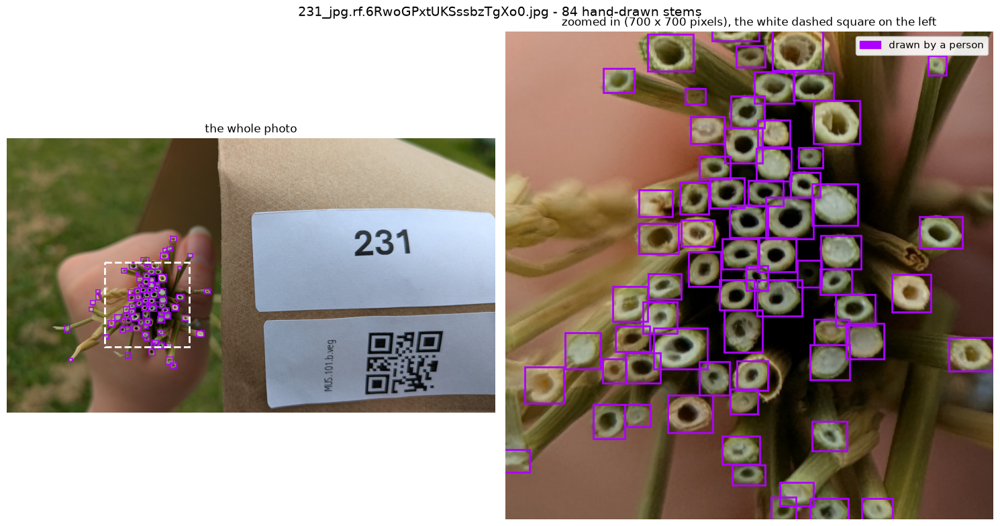

In [11]:
def show(image_array, box_groups, title, zoom=None, zoom_size=700):
    """
    Draw a photo twice: the whole thing, and a zoomed-in window.

    box_groups : a list of (boxes, colour, label) or (boxes, colour, label,
                 linestyle), where boxes are [left, top, width, height]
    zoom       : (left, top) corner of the zoom window. If left as None, the
                 window is centred on the middle of the boxes - which is where
                 there is something worth looking at.
    """
    height, width = image_array.shape[:2]

    # normalise the groups so every one has a line style
    groups = [(g[0], g[1], g[2], g[3] if len(g) > 3 else "solid") for g in box_groups]

    if zoom is None:
        all_boxes = np.concatenate([np.asarray(b, float).reshape(-1, 4)
                                    for b, *_ in groups if len(b)] or
                                   [np.zeros((0, 4))])
        if len(all_boxes):
            zoom = (np.median(all_boxes[:, 0] + all_boxes[:, 2] / 2) - zoom_size / 2,
                    np.median(all_boxes[:, 1] + all_boxes[:, 3] / 2) - zoom_size / 2)
        else:
            zoom = (width / 2 - zoom_size / 2, height / 2 - zoom_size / 2)
    zx, zy = int(zoom[0]), int(zoom[1])
    zx = max(0, min(zx, width  - zoom_size))
    zy = max(0, min(zy, height - zoom_size))

    fig, axes = plt.subplots(1, 2, figsize=(15, 8),
                             gridspec_kw={"width_ratios": [1, 1]})

    # ---------- left: the whole photo ----------
    axes[0].imshow(image_array)
    for boxes, colour, _, style in groups:
        for left, top, w, h in np.asarray(boxes, float).reshape(-1, 4):
            axes[0].add_patch(mpatches.Rectangle((left, top), w, h, linewidth=1.1,
                                                 edgecolor=colour, facecolor="none",
                                                 linestyle=style))
    # show where the zoom window is
    axes[0].add_patch(mpatches.Rectangle((zx, zy), zoom_size, zoom_size,
                                         linewidth=2.0, edgecolor="white",
                                         facecolor="none", linestyle="--"))
    axes[0].set_title("the whole photo", fontsize=12)
    axes[0].axis("off")

    # ---------- right: the zoom ----------
    axes[1].imshow(image_array[zy:zy + zoom_size, zx:zx + zoom_size])
    for boxes, colour, _, style in groups:
        for left, top, w, h in np.asarray(boxes, float).reshape(-1, 4):
            axes[1].add_patch(mpatches.Rectangle((left - zx, top - zy), w, h,
                                                 linewidth=2.0, edgecolor=colour,
                                                 facecolor="none", linestyle=style))
    axes[1].set_title(f"zoomed in ({zoom_size} x {zoom_size} pixels), "
                      "the white dashed square on the left", fontsize=12)
    axes[1].axis("off")

    if any(label for _, _, label, _ in groups):
        handles = [mpatches.Patch(facecolor=colour, edgecolor=colour, label=label)
                   for _, colour, label, _ in groups if label]
        axes[1].legend(handles=handles, loc="upper right", fontsize=11,
                       framealpha=0.9)

    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()


show(photo_array,
     [(truth_boxes, COLOR_TRUTH, "drawn by a person")],
     f"{image_filename} - {len(truth_boxes)} hand-drawn stems")

In the zoomed panel you should see a purple box (or whatever color you selected for `COLOR_TRUTH` in Step 1) sitting neatly around each cut
stem. This illustrates how the model finds the stems. A
Kernza stem cut across is a **ring** — a pale wall around a dark hollow centre. That pattern of a ring around a hole is what the model learns to recognize as a Kernza stem. The model counts Kernza stems by detecting those rings, and drawing its own bounding boxes around each one.

If the boxes are clearly in the wrong place, stop here. Something is wrong with
the annotation file or the rotation, and nothing after this point will make
sense.

---
## Step 5 — Cutting up the photo

A detector like YOLO does not look at a photo at its original size. It shrinks
whatever you hand it down to a fixed square — here, 640 × 640 pixels.

For photos of dogs and cars that is fine. For this job it is fatal -- see the explanation of stem pixel size above. The stems would become way too small for the model to detect!

Run the next cell, which will give you some specific information about the photo and stem size to demonstrate why shrinking the photo down is not a viable strategy.

In [12]:
typical_stem = float(np.median(truth_boxes[:, 2])) if len(truth_boxes) else float("nan")
shrink       = PATCH_SIZE / max(WIDTH, HEIGHT)

print(f"The photo is                      {WIDTH} x {HEIGHT} pixels")
print(f"A typical stem is about           {typical_stem:.0f} pixels across")
print(f"Shrinking the whole photo to {PATCH_SIZE} px would scale it by {shrink:.2f}x,")
print(f"which would leave each stem about {typical_stem * shrink:.0f} pixels across.")

The photo is                      4032 x 2268 pixels
A typical stem is about           49 pixels across
Shrinking the whole photo to 640 px would scale it by 0.16x,
which would leave each stem about 8 pixels across.


A few pixels across is nothing — no detector can find a ring that small, and
several stems would blur into one blob.

So instead of shrinking the whole photo, we cut it into 640 × 640 tiles at
**full resolution** and hand the model one tile at a time. Inside each tile, the average stem
is still about 35 pixels across (this may be a little more or less in your specific photo), which is a perfectly reasonable size for a
detector to find.

The tiles **overlap by half a tile** by default. The amount of overlap is determined by `OVERLAP`, which is set by default to 0.5 in Step 1. If you modified it to be, say `OVERLAP = 0.25`, then the tiles would overlap by a quarter of a tile.
The tiles need to overlap because if they didn't, i.e. if they just touched, a stem sitting on
a boundary would be sliced in two. A stem sliced in two wouldn't follow the neat ring-hole pattern described above, and so the detector would almost certainly miss it. With 50% overlap every
stem lands comfortably inside at least one tile, so we can be confident that all the stems will be counted. 

The price is that we now have
to be careful not to count the same stem twice — we deal with that in Step 6.

The cell below will divide your photo into tiles. The output gives you some information about tile size, overlap, and number of tiles.

In [63]:
def tile_origins(width, height, patch_size=PATCH_SIZE, overlap=OVERLAP):
    """
    A function to work out the top-left corner of every tile.

    Returns (x_positions, y_positions, stride).
    'stride' is how far we move between tiles: with a 640 px tile and 50%
    overlap the step is 320 px, so every tile shares half its area with its
    neighbour.

    The last tile in each direction is pushed flush against the edge of the
    photo, so the very edge is never left out.
    """
    stride = int(patch_size * (1 - overlap))

    x_positions = list(range(0, max(1, width  - patch_size + 1), stride))
    y_positions = list(range(0, max(1, height - patch_size + 1), stride))

    if width  > patch_size and x_positions[-1] != width  - patch_size:
        x_positions.append(width  - patch_size)
    if height > patch_size and y_positions[-1] != height - patch_size:
        y_positions.append(height - patch_size)

    return x_positions, y_positions, stride


x_positions, y_positions, stride = tile_origins(WIDTH, HEIGHT)

print(f"tile size          : {PATCH_SIZE} x {PATCH_SIZE} pixels")
print(f"step between tiles : {stride} pixels ({int(OVERLAP*100)}% overlap)")
print(f"tiles across       : {len(x_positions)}")
print(f"tiles down         : {len(y_positions)}")
print(f"tiles in total     : {len(x_positions) * len(y_positions)}")

stride: 320
x positions plot: [0, 320, 640, 960, 1280, 1600, 1920, 2240, 2560, 2880, 3200, 3520]
y positions plot: [0, 320, 640, 960, 1280, 1600, 1920]
x positions from function: [0, 320, 640, 960, 1280, 1600, 1920, 2240, 2560, 2880, 3200, 3392]
y positions from function: [0, 320, 640, 960, 1280, 1600, 1628]
tile size          : 640 x 640 pixels
step between tiles : 320 pixels (50% overlap)
tiles across       : 12
tiles down         : 7
tiles in total     : 84


The cell below will display your photo, with a grid showing the tiles created above drawn on top. Every tile is composed of four of the red squares. Two
neighbours are filled in so you can see how much they share.

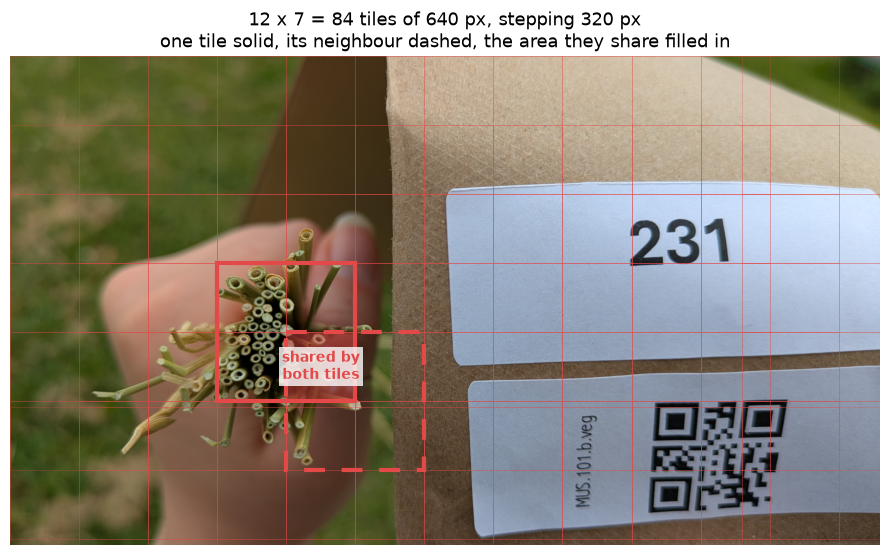

In [105]:
fig, ax = plt.subplots(figsize=(9, 12))
ax.imshow(photo_array)

# every tile, drawn faintly
for y in y_positions:
    for x in x_positions:
        ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
                                        linewidth=0.6, edgecolor=COLOR_TILE,
                                        facecolor="none", alpha=0.30))

'''
# have every other patch be solid or dashed for the first row and column of patches
for iy in range(len(y_positions)):
    for jx in range(len(x_positions)):
        y = y_positions[iy]
        x = x_positions[jx]
        if y == 0 and jx % 2 == 0:
            ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
                                        linewidth=3, edgecolor="blue",
                                        facecolor="none", linestyle="solid",
                                           alpha = 0.3))
        elif y == 0 and jx % 2 != 0:
            ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
                                        linewidth=3, edgecolor="purple",
                                        facecolor="none", linestyle=(5,(10,3)),
                                           alpha = 0.7))
        if iy % 2 == 0 and x == 0:
            ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
                                        linewidth=3, edgecolor="blue",
                                        facecolor="none", linestyle="solid",
                                           alpha = 0.3))
        elif iy % 2 != 0 and x == 0:
            ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
                                        linewidth=3, edgecolor="orange",
                                        facecolor="none", linestyle=(5,(10,3)),
                                           alpha = 0.7))
'''

        # elif iy % 2 == 0 and jx % 2 != 0:
        #     ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
        #                                 linewidth=3, edgecolor="purple",
        #                                 facecolor="none", linestyle=":"))
        # elif y == 0 and jx % 2 != 0:
        #     ax.add_patch(mpatches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE,
        #                                 linewidth=3, edgecolor=COLOR_TILE,
        #                                 facecolor="none", linestyle=":"))

# y_even, y_odd = y_positions[::2], y_positions[1::2]
# x_even, x_odd = x_positions[::2], x_positions[1::2]

# print(f"y all: [{y_positions}]")
# print(f"y even: [{y_even}]")
# print(f"y odd: [{y_odd}]")
# print(HEIGHT)

# ax.hlines(y_even, xmin=0, xmax=WIDTH, linestyle="solid",alpha = 0.5)
# ax.hlines(y_odd, xmin=0, xmax=WIDTH, linestyle="--")

# ax.vlines(x_even, ymin=0, ymax=HEIGHT, linestyle="solid", alpha = 0.5)
# ax.vlines(x_odd, ymin=0, ymax=HEIGHT, linestyle="--")

# two neighbouring tiles, picked near the stems so the picture is informative
if len(truth_boxes):
    mid_x = np.median(truth_boxes[:, 0] + truth_boxes[:, 2] / 2)
    mid_y = np.median(truth_boxes[:, 1] + truth_boxes[:, 3] / 2)
else:
    mid_x, mid_y = WIDTH / 2, HEIGHT / 2
a_x = min(x_positions, key=lambda x: abs(x + PATCH_SIZE / 2 - mid_x))
a_y = min(y_positions, key=lambda y: abs(y + PATCH_SIZE / 2 - mid_y))
b_x, b_y = a_x + stride, a_y + stride


for (hx, hy), style in [((a_x, a_y), "solid"), ((b_x, b_y), (0, (5, 4)))]:
    ax.add_patch(mpatches.Rectangle((hx, hy), PATCH_SIZE, PATCH_SIZE,
                                    linewidth=3.0, edgecolor=COLOR_TILE,
                                    facecolor="none", linestyle=style))

# the area those two tiles share - filling only this makes the overlap obvious
ax.add_patch(mpatches.Rectangle((b_x, b_y), PATCH_SIZE - stride, PATCH_SIZE - stride,
                                linewidth=0, facecolor=COLOR_TILE, alpha=0.45))
ax.text(b_x + (PATCH_SIZE - stride) / 2, b_y + (PATCH_SIZE - stride) / 2,
        "shared by\nboth tiles", color=COLOR_TILE, fontsize=10,
        fontweight="bold", ha="center", va="center",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.80, pad=2))

ax.set_title(f"{len(x_positions)} x {len(y_positions)} = "
             f"{len(x_positions)*len(y_positions)} tiles of {PATCH_SIZE} px, "
             f"stepping {stride} px\n"
             "one tile solid, its neighbour dashed, the area they share filled in",
             fontsize=13)
ax.axis("off") #commented out for testing
plt.tight_layout()
plt.show()

Now we actually cut the tiles out, and translate the coordinates of the hand-drawn bounding boxes within each tile into the coordinate system of that tile. For example, say you have a bounding box with center coordinates (700 px, 800 px). That bounding box is 700 pixels from the left of the photograph, and 800 pixels from the bottom of the photograph. The box is inside a tile that starts at the coordinates (640 px, 640 px). In that tile's coordinate system, the bounding box's coordinates are (60 px, 160 px), because the box is 60 pixels from the left of the tile, and 160 pixels from the bottom of the tile.

Two details in the function below are worth knowing about:

- **A tile only gets a box if the tile contains the bounding box's center.** Without
  this, a tile that clips the last 3 pixels of a stem at its edge would be
  handed a 3-pixel-wide "stem" to learn from, which is worse than useless.
- **Bounding boxes are trimmed at the edge of the tile.** If a stem straddles the boundary between two tiles, the
  part inside the tile is kept.

Note what these rules do *not* do. Because the tiles overlap, a stem sits
comfortably inside **several** tiles, and each of those tiles legitimately
lists it. That is correct here: each tile is a separate picture, and every
stem visible in a picture should be marked in it.

It does mean you cannot count stems by adding up the tiles — you would count
most of them three or four times over. Solving that is what step 8 is for, and
is governed by a different rule from those listed here. Understanding the difference between these two different procedures is one of hte most important parts of this tutorial.

The output of the cell below will tell you how many tiles your photo has been divided into; how many of those tiles contained at least one bounding box (i.e., contained at least one stem); and the total number of bounding boxes counted across all tiles. Note that the number of bounding boxes across all tiles should be considerably higher that the number of hand-drawn bounding boxes. This is because of the rules described above: each bounding box is counted in multiple tiles.

Finally, the output shows the number of bounding boxes, i.e. stems, that were not counted in any tile. This number should always be zero. It also shows the number of tiles any one stem typically appears on.

In [107]:
def cut_into_tiles(image_array, boxes, patch_size=PATCH_SIZE, overlap=OVERLAP):
    """
    Cut a photo into overlapping tiles and move the boxes into tile coordinates.

    boxes : [left, top, width, height] in photo coordinates

    Returns (tiles, boxes_per_tile, origins) - three lists of the same length.
    """
    height, width = image_array.shape[:2]
    x_positions, y_positions, _ = tile_origins(width, height, patch_size, overlap)

    tiles, boxes_per_tile, origins = [], [], []

    for y in y_positions:
        for x in x_positions:
            tile = image_array[y:y + patch_size, x:x + patch_size]

            tile_left,  tile_top    = x, y
            tile_right, tile_bottom = x + patch_size, y + patch_size

            boxes_here = []
            for box_left, box_top, box_w, box_h in np.asarray(boxes, float).reshape(-1, 4):
                box_right  = box_left + box_w
                box_bottom = box_top  + box_h

                # the part of the box that lies inside this tile
                inside_left   = max(box_left,   tile_left)
                inside_top    = max(box_top,    tile_top)
                inside_right  = min(box_right,  tile_right)
                inside_bottom = min(box_bottom, tile_bottom)

                if inside_right <= inside_left or inside_bottom <= inside_top:
                    continue                      # no overlap at all

                # is the box's centre inside this tile? If not, this tile is
                # only clipping the edge of a stem that sits mostly elsewhere,
                # so leave it out rather than learn from a sliver.
                centre_x = box_left + box_w / 2
                centre_y = box_top  + box_h / 2
                if not (tile_left <= centre_x < tile_right and
                        tile_top  <= centre_y < tile_bottom):
                    continue

                boxes_here.append([inside_left - x, inside_top - y,
                                   inside_right - inside_left,
                                   inside_bottom - inside_top])

            tiles.append(tile)
            boxes_per_tile.append(boxes_here)
            origins.append((x, y))

    return tiles, boxes_per_tile, origins


tiles, boxes_per_tile, origins = cut_into_tiles(photo_array, truth_boxes)

with_stems    = [i for i, b in enumerate(boxes_per_tile) if len(b) > 0]
without_stems = [i for i, b in enumerate(boxes_per_tile) if len(b) == 0]

# the fullest tiles first - those are the interesting ones to look at
busiest = sorted(with_stems, key=lambda i: -len(boxes_per_tile[i]))

print(f"tiles cut                    : {len(tiles)}")
print(f"tiles with at least one stem : {len(with_stems)}")
print(f"tiles with no stems at all   : {len(without_stems)}")
print(f"total number bounding boxes, counted across all tiles: {sum(len(b) for b in boxes_per_tile)}")

# --- the check that matters: is every stem on at least one tile? ---
if len(truth_boxes):
    centres = np.column_stack([truth_boxes[:, 0] + truth_boxes[:, 2] / 2,
                               truth_boxes[:, 1] + truth_boxes[:, 3] / 2])
    appearances = np.zeros(len(truth_boxes), dtype=int)
    for x, y in origins:
        appearances += ((centres[:, 0] >= x) & (centres[:, 0] < x + PATCH_SIZE) &
                        (centres[:, 1] >= y) & (centres[:, 1] < y + PATCH_SIZE))

    print()
    print(f"stems that landed on no tile at all: {(appearances == 0).sum()}"
          f"   (must be 0 - a stem on no tile can never be found)")
    print(f"tiles a stem typically appears on  : {int(np.median(appearances))}"
          f"   (more than 1, because tiles overlap)")

tiles cut                    : 84
tiles with at least one stem : 28
tiles with no stems at all   : 56
total number bounding boxes, counted across all tiles: 358

stems that landed on no tile at all: 0   (must be 0 - a stem on no tile can never be found)
tiles a stem typically appears on  : 4   (more than 1, because tiles overlap)


Read those last two numbers carefully, because they are the whole point.

**No stem landed on zero tiles.** Every stem gets its chance to be seen. That
is what the 50% overlap buys.

**A typical stem appears on multiple tiles.** If you're using our example, a typical stem appears on four tiles. In other words, the total number of bounding boxes, summed
across all the tiles, is roughly four times the number of stems in the photo. That
is not a mistake — it is the overlap working as intended. It is also exactly
why counting stems cannot simply add up the number of bounding boxes over all the tiles.

### The tiles, with the hand-drawn boxes on them

**This is what the model actually sees.** To show you some examples, here are nine tiles that contain stems:

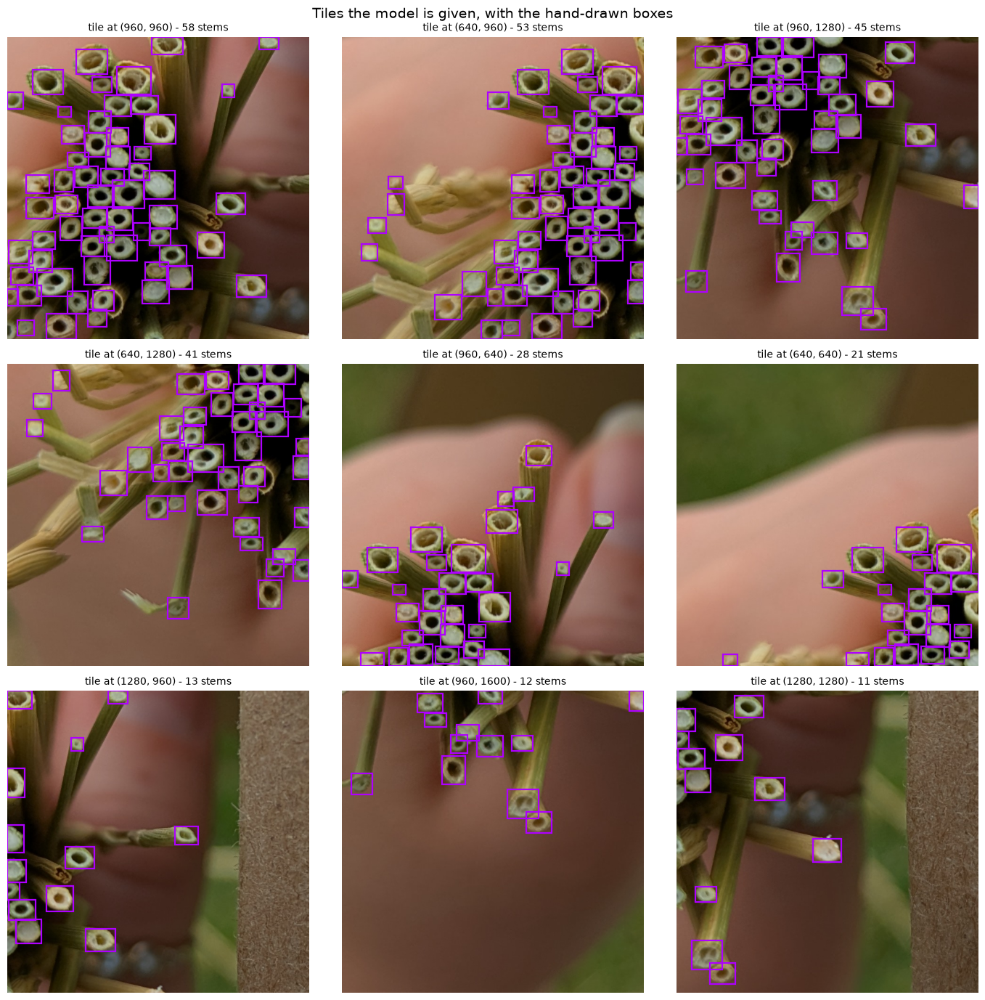

In [108]:
chosen = busiest[:9]

fig, axes = plt.subplots(3, 3, figsize=(14, 14))
for ax, index in zip(axes.flatten(), chosen):
    ax.imshow(tiles[index])
    for left, top, w, h in boxes_per_tile[index]:
        ax.add_patch(mpatches.Rectangle((left, top), w, h, linewidth=1.6,
                                        edgecolor=COLOR_TRUTH, facecolor="none"))
    ax.set_title(f"tile at {origins[index]} - {len(boxes_per_tile[index])} stems",
                 fontsize=10)
    ax.axis("off")
for ax in axes.flatten()[len(chosen):]:
    ax.axis("off")

fig.suptitle("Tiles the model is given, with the hand-drawn boxes",
             fontsize=14)
fig.tight_layout()
plt.show()

### A tile with nothing in it

Most tiles in a photo like this contain no stems at all — instead, they show a bag, hand, label,
chaff, or something else unrelated. The model has to learn to say "no stems here" just as reliably
as it says "stem here", so these tiles matter too. Below are a couple examples of tiles with no stems in them.

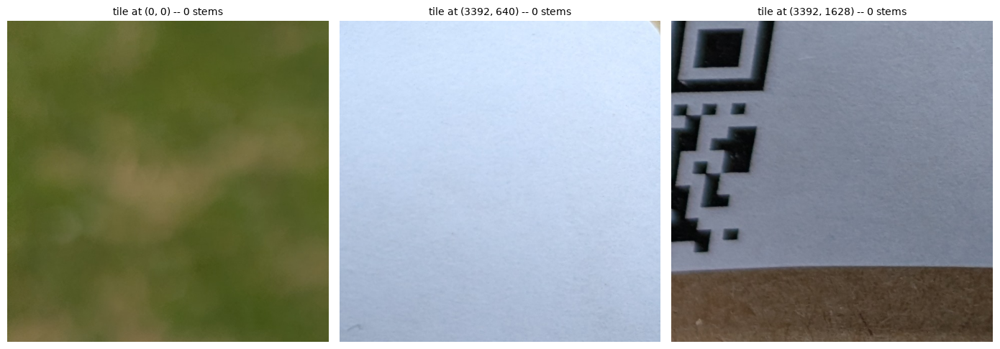

In [119]:
if without_stems:
    choose_nostems = [without_stems[0], without_stems[len(without_stems)//2], without_stems[len(without_stems)-1]]

    fig, axes = plt.subplots(1, 3, figsize=(14, 14))
    for ax, index in zip(axes.flatten(), choose_nostems):
        ax.imshow(tiles[index])
        for left, top, w, h in boxes_per_tile[index]:
            ax.add_patch(mpatches.Rectangle((left, top), w, h, linewidth=1.6,
                                            edgecolor=COLOR_TRUTH, facecolor="none"))
        ax.set_title(f"tile at {origins[index]} -- {len(boxes_per_tile[index])} stems",
                     fontsize=10)
        ax.axis("off")
    for ax in axes.flatten()[len(choose_nostems):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Every tile in this photo contains at least one stem, so there are no example stem-less tiles to show here.")

---
## Step 6 — The model

### What it is

The starting point is **YOLO26-nano**, an off-the-shelf object detector.
"Nano" is the smallest member of the family: fewest internal numbers, quick
enough to run on a laptop. YOLO looks at a square image once and reports every
object it can find, each as a box plus a confidence score between 0 and 1.

### What was changed, and why

Off the shelf, YOLO26 is set up to tell 80 kinds of thing apart — person, car,
dog, and so on. Its head therefore ends in a layer with 80 outputs, one score
per kind.

We only care about one kind of thing: a stem. So the last layer of that
branch is replaced with one that has a **single** output. Nothing else about
the network changes.

There are **two** such branches to fix, `cv3` and `one2one_cv3`, because
YOLO26's head is doubled: one branch is used while training, the other
produces the final answers. Miss one and the model will not load.

### Then the trained numbers go in

Rebuilding the shape gives an empty network that predicts nonsense. The
`.pt` file holds the numbers learned from the annotated Kernza photos, and
loading it fills every slot in that shape.

The two counts the next cell prints are your check that it worked:

- **slots the file did not fill = 0** — every part of the network got its numbers
- **numbers with nowhere to go = 0** — every number in the file found its place

If either is not zero, the model and the file do not match, and the cell stops
with an error rather than quietly giving you rubbish.

In [15]:
def replace_class_branch(branch_list):
    """
    Swap the last layer of each 'what is this?' branch for one that has a
    single output instead of eighty.
    """
    for i in range(len(branch_list)):
        old_layer = branch_list[i][-1]
        new_layer = nn.Conv2d(
            in_channels=old_layer.in_channels,
            out_channels=1,                      # <-- one class: "stem"
            kernel_size=old_layer.kernel_size,
            stride=old_layer.stride,
            padding=old_layer.padding,
            bias=(old_layer.bias is not None),
        )
        nn.init.normal_(new_layer.weight, mean=0.0, std=0.01)
        if new_layer.bias is not None:
            nn.init.constant_(new_layer.bias, 0.0)
        branch_list[i][-1] = new_layer


def build_model(weights_path, device):
    """Build the one-class YOLO26-nano and load the trained numbers into it."""
    # 1. An empty YOLO26-nano, built from its blueprint file.
    wrapper = YOLO("yolo26n.yaml")
    if hasattr(wrapper.model, "args"):
        wrapper.model.args["nc"] = 1          # nc = "number of classes"
    model = wrapper.model

    # 2. Tell the head there is only one class, and rebuild both branches.
    head = model.model[-1]
    head.nc = 1
    if hasattr(head, "cv3"):
        replace_class_branch(head.cv3)
    if hasattr(head, "one2one_cv3"):
        replace_class_branch(head.one2one_cv3)

    # 3. Ask for end-to-end predictions, explicitly.
    #
    #    YOLO26's head has two branches. The one-to-one branch gives one box per
    #    object and needs no overlap filtering; the one-to-many branch gives
    #    many overlapping boxes that must be filtered afterwards. Which one the
    #    model uses is controlled by a flag whose DEFAULT CHANGED between
    #    Ultralytics releases: 8.4.138 defaulted to the one-to-one branch,
    #    8.4.153 defaults to the one-to-many branch and expects you to opt in.
    #
    #    Setting the flag makes the answer identical on every version. Without
    #    it, two computers with different Ultralytics versions silently produce
    #    completely different output from the same weights and the same photo.
    if hasattr(head, "one2one_cv3"):
        head._end2end = True

    # 4. Pour the trained numbers in.
    #
    #    About "weights_only": PyTorch 2.6 and later refuse to unpickle anything
    #    but plain tensors unless you say weights_only=False, while PyTorch
    #    before 1.13 does not know the argument at all and raises TypeError if
    #    you pass it. Asking torch.load which one this is keeps the notebook
    #    working on both, which matters because dropping the argument silently
    #    breaks any checkpoint that stores a whole model rather than a plain
    #    list of tensors.
    if "weights_only" in inspect.signature(torch.load).parameters:
        saved = torch.load(weights_path, map_location="cpu", weights_only=False)
    else:
        saved = torch.load(weights_path, map_location="cpu")
    if isinstance(saved, nn.Module):
        saved = saved.state_dict()
    missing, unexpected = model.load_state_dict(saved, strict=False)

    print(f"Loaded {len(saved)} groups of trained numbers.")
    print(f"  slots the file did not fill : {len(missing)}   (should be 0)")
    print(f"  numbers with nowhere to go  : {len(unexpected)}   (should be 0)")
    if missing or unexpected:
        raise RuntimeError(
            "The model we built does not match the file we loaded.\n"
            "This almost always means the weights file is for a different model.\n"
            f"  example unfilled slot: {missing[:1]}\n"
            f"  example spare number : {unexpected[:1]}"
        )

    return model.to(device).eval()           # .eval() = "we are predicting, not training"


model = build_model(WEIGHTS_PATH, DEVICE)
print("\nModel ready.")

Loaded 708 groups of trained numbers.
  slots the file did not fill : 0   (should be 0)
  numbers with nowhere to go  : 0   (should be 0)

Model ready.


---
## Step 7 — Find stems in the tiles

Now we hand tiles to the model.

Three small things happen on the way in: the tile's colour values are put on a
0-to-1 scale instead of 0-to-255, the dimensions are reordered into the layout
the model expects, and we tell PyTorch we are predicting rather than training.

On the way out, the model gives one row per candidate stem. The first four
numbers are the box, the fifth is the confidence. We keep only rows whose
confidence is above `CONFIDENCE` (0.45).

One trap to be aware of: the model reports boxes as **two corners**
(`left, top, right, bottom`), while the annotation file uses **a corner and a
size** (`left, top, width, height`). Both are four numbers and neither
complains if you mix them up — you just get boxes in odd places. The little
converter below keeps them straight.

In [16]:
def detect_on_tile(tile, model, device, confidence=CONFIDENCE):
    """
    Run the model on one square tile.

    Returns
      boxes  : an array with one row per stem, holding [left, top, right, bottom]
      scores : how sure the model is about each one, between 0 and 1
    """
    # If the tile is smaller than expected (only possible for a very small
    # photo), pad it with black so the model gets the size it wants.
    pad_y = PATCH_SIZE - tile.shape[0]
    pad_x = PATCH_SIZE - tile.shape[1]
    if pad_y > 0 or pad_x > 0:
        tile = np.pad(tile, ((0, pad_y), (0, pad_x), (0, 0)))

    # Rearrange the tile into the shape the model expects, and put the colour
    # values on a 0-1 scale instead of 0-255.
    batch = torch.from_numpy(np.ascontiguousarray(tile))
    batch = batch.permute(2, 0, 1).float().div(255.0).unsqueeze(0).to(device)

    with torch.no_grad():                    # we are not training, so don't track gradients
        output = model(batch)

    raw = output[0][0] if isinstance(output, tuple) else output[0]
    if raw.dim() == 2 and raw.shape[0] == 6 and raw.shape[1] != 6:
        raw = raw.T                          # sometimes it arrives sideways

    # Check the shape rather than trusting it. We expect one row per candidate
    # stem and six columns: left, top, right, bottom, confidence, class. If the
    # model returns something else, the arithmetic below would still run and
    # would still produce numbers - they would simply be meaningless. Stopping
    # here with an explanation is far better than a silently wrong count.
    if raw.dim() != 2 or raw.shape[1] != 6:
        raise RuntimeError(
            f"The model returned an unexpected shape: {tuple(raw.shape)}.\n"
            "Expected one row per detection and six columns.\n"
            "This almost always means the end-to-end flag did not take effect, "
            "usually because of an Ultralytics version change. Check that "
            "build_model() sets head._end2end = True, and compare the "
            "Ultralytics version against the one in requirements-lock.txt."
        )

    keep = raw[:, 4] > confidence            # column 4 is the confidence score
    boxes  = raw[keep][:, :4].cpu()
    scores = raw[keep][:, 4].cpu()
    return boxes, scores


def xyxy_to_xywh(boxes):
    """
    Turn [left, top, right, bottom] boxes into [left, top, width, height].

    Two conventions, one shape. The annotation file uses corner-plus-size; the
    model reports two opposite corners; matplotlib wants corner-plus-size. This
    is the single most common source of boxes drawn in the wrong place.
    """
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    out = boxes.copy()
    out[:, 2] = boxes[:, 2] - boxes[:, 0]
    out[:, 3] = boxes[:, 3] - boxes[:, 1]
    return out

Try it on a single tile first — the same tile that appeared at the top-left of
the nine-tile grid above.

tile at (960, 960)
  stems the person marked : 58
  stems the model found   : 59
  confidence range        : 0.65 to 0.93


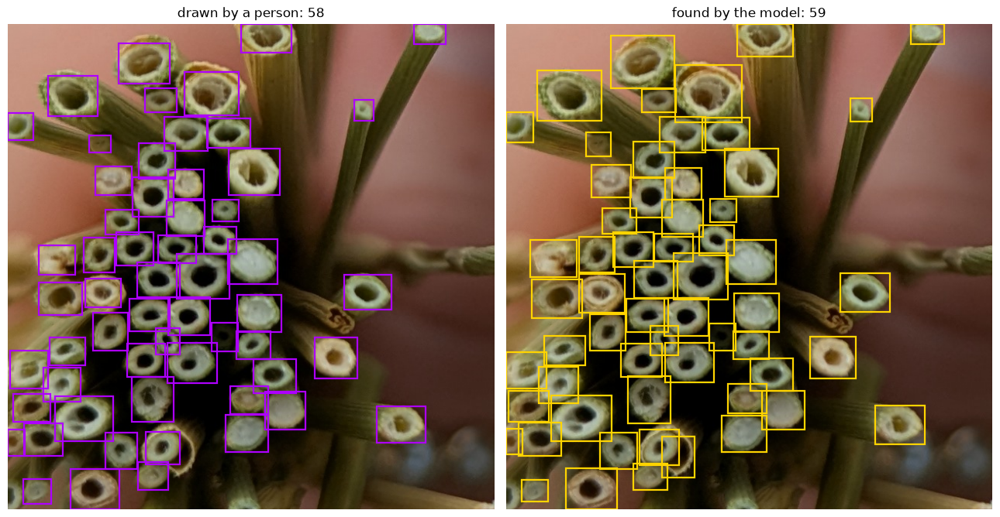

In [17]:
index = busiest[0]

boxes_xyxy, scores = detect_on_tile(tiles[index], model, DEVICE)

print(f"tile at {origins[index]}")
print(f"  stems the person marked : {len(boxes_per_tile[index])}")
print(f"  stems the model found   : {len(boxes_xyxy)}")
if len(scores):
    print(f"  confidence range        : {scores.min():.2f} to {scores.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 6.8))

axes[0].imshow(tiles[index])
for left, top, w, h in boxes_per_tile[index]:
    axes[0].add_patch(mpatches.Rectangle((left, top), w, h, linewidth=1.6,
                                         edgecolor=COLOR_TRUTH, facecolor="none"))
axes[0].set_title(f"drawn by a person: {len(boxes_per_tile[index])}", fontsize=12)
axes[0].axis("off")

axes[1].imshow(tiles[index])
for left, top, w, h in xyxy_to_xywh(boxes_xyxy):
    axes[1].add_patch(mpatches.Rectangle((left, top), w, h, linewidth=1.6,
                                         edgecolor=COLOR_PREDICTION, facecolor="none"))
axes[1].set_title(f"found by the model: {len(boxes_xyxy)}", fontsize=12)
axes[1].axis("off")

fig.tight_layout()
plt.show()

Now the same thing on nine tiles at once, so you can get a feel for where the
model does well and where it struggles.

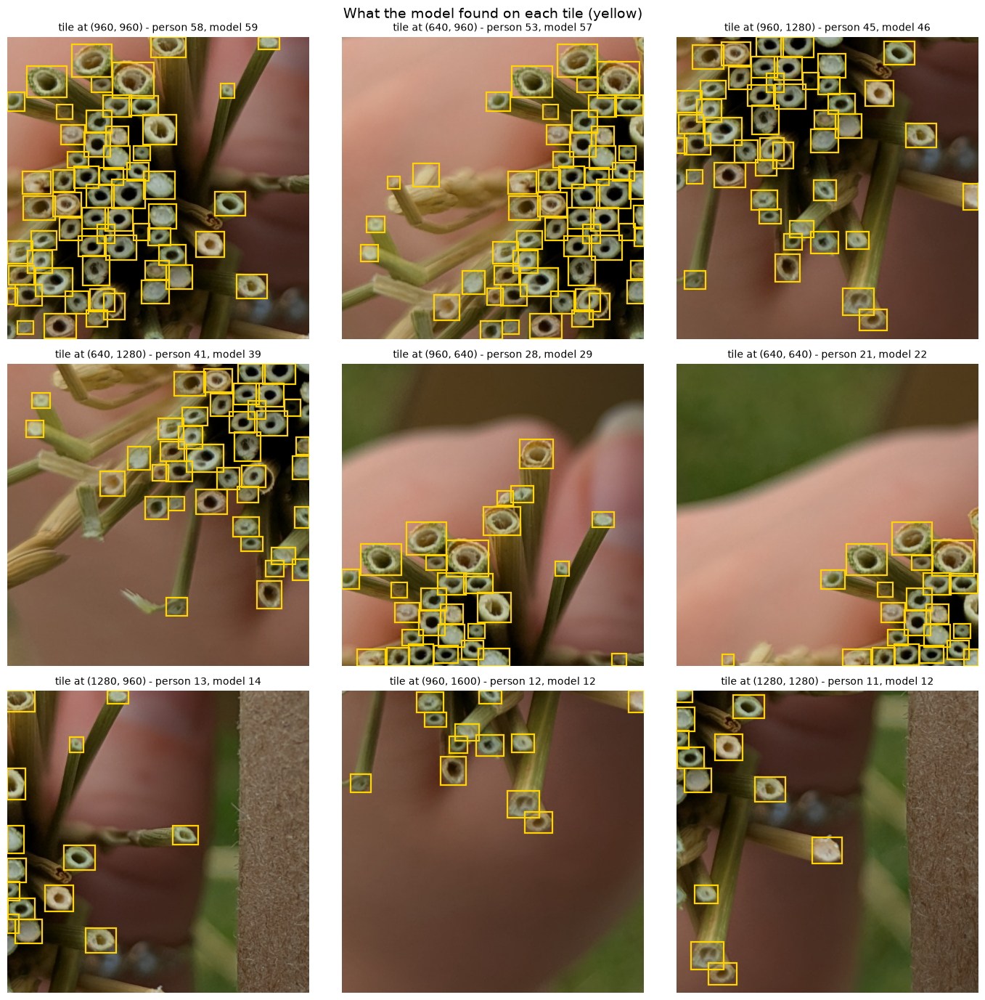

In [18]:
chosen = busiest[:9]

fig, axes = plt.subplots(3, 3, figsize=(14, 14))
for ax, index in zip(axes.flatten(), chosen):
    boxes_xyxy, _ = detect_on_tile(tiles[index], model, DEVICE)
    ax.imshow(tiles[index])
    for left, top, w, h in xyxy_to_xywh(boxes_xyxy):
        ax.add_patch(mpatches.Rectangle((left, top), w, h, linewidth=1.6,
                                        edgecolor=COLOR_PREDICTION, facecolor="none"))
    ax.set_title(f"tile at {origins[index]} - "
                 f"person {len(boxes_per_tile[index])}, model {len(boxes_xyxy)}",
                 fontsize=10)
    ax.axis("off")
for ax in axes.flatten()[len(chosen):]:
    ax.axis("off")

fig.suptitle("What the model found on each tile (yellow)", fontsize=14)
fig.tight_layout()
plt.show()

Do not read too much into a per-tile disagreement. A stem near a tile edge may
be listed for the *neighbouring* tile under the centre rule, while the model
happily reports it on both. Sorting that out is exactly what the next step is
for.

---
## Step 8 — Put the tiles back together

We now have detections on every tile separately, and we want one count for the
whole photo. Three things have to happen.

**1. Move every box back into the photo's coordinates.** A box 60 pixels from
the left of a tile that starts at 640 is 700 pixels from the left of the photo.
Just addition.

**2. Decide which tile owns each detection.** Neighbouring tiles share half
their area, so the same stem is genuinely found two, three, sometimes four
times. The rule: each tile has an **inner zone**, and a tile only keeps
detections whose centre falls in *its* inner zone. The zone is the tile shrunk
by half a step (160 pixels) on each side. Because the zones sit half a step
apart, they cover the photo without stacking on top of each other — a stem
falls in exactly one zone, so exactly one tile claims it.

Tiles on the outside edge of the photo are the exception: there is no
neighbour out there to hand the work to, so an edge tile trusts all the way out
to the border. Otherwise a strip round the outside of every photo would be
ignored.

**3. Remove any duplicates that are left.** Finally, look at all the surviving
boxes together: wherever two boxes overlap by more than `NMS_IOU` (half their
combined area), keep the more confident one and drop the other. This is called
*non-maximum suppression*, and it is the safety net for the two places rule 2
cannot fully handle: the last row and column of tiles are pushed flush against
the photo edge, so they sit closer to their neighbour than a normal step and
their inner zones overlap slightly.

The picture below is that idea with two tiles instead of 108.

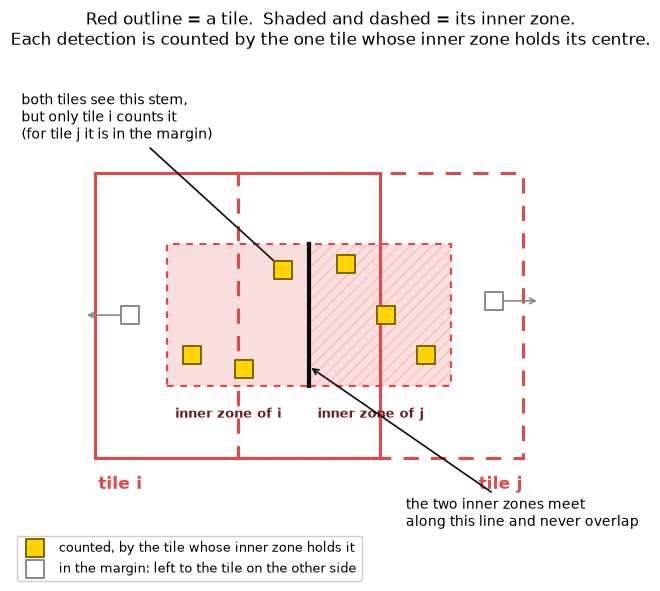

In [19]:
# A drawing of the rule. Not real data - just the idea, with two side-by-side
# tiles. Real tiles are neighbours in both directions; the idea is the same.
fig, ax = plt.subplots(figsize=(11, 6))

tile, step = 1.0, 0.5          # one tile wide, neighbours half a tile apart
margin = step / 2              # the strip along each edge a tile does NOT trust

for (ox, name, style, hatch, lab_x, lab_ha) in [
        (0.0,  "tile i", "solid",     None,  0.01,        "left"),
        (step, "tile j", (0, (5, 4)), "///", step + tile, "right")]:
    ax.add_patch(mpatches.Rectangle((ox, 0), tile, tile, linewidth=2.2,
                                    edgecolor=COLOR_TILE, facecolor="none",
                                    linestyle=style))
    ax.add_patch(mpatches.Rectangle((ox + margin, margin),
                                    tile - 2 * margin, tile - 2 * margin,
                                    linewidth=0, facecolor=COLOR_TILE, alpha=0.18,
                                    hatch=hatch, edgecolor=COLOR_TILE))
    ax.add_patch(mpatches.Rectangle((ox + margin, margin),
                                    tile - 2 * margin, tile - 2 * margin,
                                    linewidth=1.6, edgecolor=COLOR_TILE,
                                    facecolor="none", linestyle=(0, (3, 3))))
    ax.text(lab_x, -0.11, name, color=COLOR_TILE, ha=lab_ha,
            fontsize=12, fontweight="bold")

ax.text(margin + 0.03, margin - 0.11, "inner zone of i",
        fontsize=9.5, color="#6b1f1f", fontweight="bold")
ax.text(step + margin + 0.03, margin - 0.11, "inner zone of j",
        fontsize=9.5, color="#6b1f1f", fontweight="bold")

# the two inner zones share this edge - they meet, and do not overlap
ax.plot([step + margin, step + margin], [margin, tile - margin],
        color="#0b0b0b", linewidth=3.0, zorder=6)
ax.annotate("the two inner zones meet\nalong this line and never overlap",
            xy=(step + margin, 0.32), xytext=(step + margin + 0.34, -0.24),
            fontsize=10, ha="left",
            arrowprops=dict(arrowstyle="->", color="#0b0b0b", linewidth=1.2))

# --- the detections -------------------------------------------------------
kept_i     = [(0.34, 0.36), (0.52, 0.31)]
kept_j     = [(0.88, 0.68), (1.16, 0.36), (1.02, 0.50)]
shared     = [(0.66, 0.66)]          # inside BOTH tiles, in i's inner zone
declined   = [(0.12, 0.50), (1.40, 0.55)]

ax.scatter(*zip(*(kept_i + kept_j + shared)), s=150, marker="s",
           facecolor=COLOR_PREDICTION, edgecolor="#7a6500", linewidth=1.4,
           zorder=7, label="counted, by the tile whose inner zone holds it")
ax.scatter(*zip(*declined), s=150, marker="s", facecolor="white",
           edgecolor="#8a8a85", linewidth=1.4, zorder=7,
           label="in the margin: left to the tile on the other side")

ax.annotate("both tiles see this stem,\nbut only tile i counts it\n"
            "(for tile j it is in the margin)",
            xy=shared[0], xytext=(-0.26, 1.12), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="#0b0b0b", linewidth=1.2))
for dx, dy in declined:
    ax.annotate("", xy=(dx + (0.16 if dx > 1 else -0.16), dy), xytext=(dx, dy),
                arrowprops=dict(arrowstyle="->", color="#8a8a85", linewidth=1.2))

ax.set_xlim(-0.30, 1.95)
ax.set_ylim(-0.42, 1.42)
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="lower left", fontsize=9.5, framealpha=0.95,
          bbox_to_anchor=(0.0, -0.02))
ax.set_title("Red outline = a tile.  Shaded and dashed = its inner zone.\n"
             "Each detection is counted by the one tile whose inner zone holds "
             "its centre.", fontsize=12)
plt.tight_layout()
plt.show()

And here is the whole thing as one function. This is the code that produced the
counts in the paper.

In [20]:
def count_stems(photo_array, model, device,
                confidence=CONFIDENCE, nms_iou=NMS_IOU,
                patch_size=PATCH_SIZE, overlap=OVERLAP):
    """
    The whole pipeline for one photo: cut into tiles, detect on each tile,
    keep each detection once, then remove duplicates.

    Returns
      boxes  : [left, top, right, bottom] for every stem, in photo coordinates
      scores : the confidence of each one
    """
    height, width, _ = photo_array.shape
    x_positions, y_positions, stride = tile_origins(width, height, patch_size, overlap)
    margin = stride / 2

    kept_boxes, kept_scores = [], []

    for y in y_positions:
        for x in x_positions:
            tile = photo_array[y:y + patch_size, x:x + patch_size]
            boxes, scores = detect_on_tile(tile, model, device, confidence)

            if len(boxes):
                # ---- step 2: does this tile own the detection? ----
                centre_x = (boxes[:, 0] + boxes[:, 2]) / 2
                centre_y = (boxes[:, 1] + boxes[:, 3]) / 2

                # A tile trusts its inner zone. On the outside edge of the photo
                # there is no neighbour to hand work to, so it trusts all the
                # way out to the border.
                left_limit   = 0          if x == 0                        else margin
                right_limit  = patch_size if (x + patch_size) >= width     else patch_size - margin
                top_limit    = 0          if y == 0                        else margin
                bottom_limit = patch_size if (y + patch_size) >= height    else patch_size - margin

                mine = ((centre_x >= left_limit) & (centre_x < right_limit) &
                        (centre_y >= top_limit)  & (centre_y < bottom_limit))
                boxes, scores = boxes[mine], scores[mine]

            if len(boxes):
                # ---- step 1: move from tile coordinates to photo coordinates ----
                boxes = boxes.clone()
                boxes[:, [0, 2]] += x
                boxes[:, [1, 3]] += y
                kept_boxes.append(boxes)
                kept_scores.append(scores)

    if not kept_boxes:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.float32)

    all_boxes  = torch.cat(kept_boxes)
    all_scores = torch.cat(kept_scores)

    # ---- step 3: if two boxes overlap a lot, they are one stem ----
    survivors = torchvision.ops.nms(all_boxes, all_scores, nms_iou)

    return all_boxes[survivors].numpy(), all_scores[survivors].numpy()


started = time.time()
model_boxes, model_scores = count_stems(photo_array, model, DEVICE)
elapsed = time.time() - started

print(f"Counted {len(model_boxes)} stems in {elapsed:.1f} seconds "
      f"({len(x_positions)*len(y_positions)} tiles on {DEVICE}).")
if len(model_scores):
    print(f"Confidence of the counted stems: {model_scores.min():.2f} to {model_scores.max():.2f}")

Counted 84 stems in 9.4 seconds (84 tiles on cpu).
Confidence of the counted stems: 0.64 to 0.93


---
## Step 9 — The result

Three pictures: what the person marked, what the model found, and the two on
top of each other. The overlay is the one to look at.

In [21]:
model_boxes_xywh = xyxy_to_xywh(model_boxes)

difference = len(model_boxes) - len(truth_boxes)
print(f"drawn by a person : {len(truth_boxes)}")
print(f"found by the model: {len(model_boxes)}")
print(f"difference        : {difference:+d}"
      f"   ({100 * difference / max(1, len(truth_boxes)):+.1f}% of the marked count)")

drawn by a person : 84
found by the model: 84
difference        : +0   (+0.0% of the marked count)


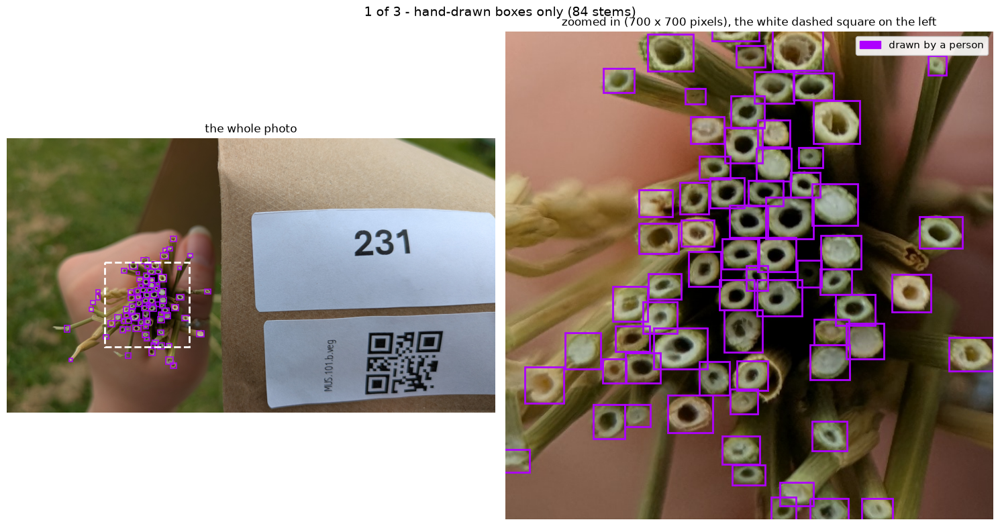

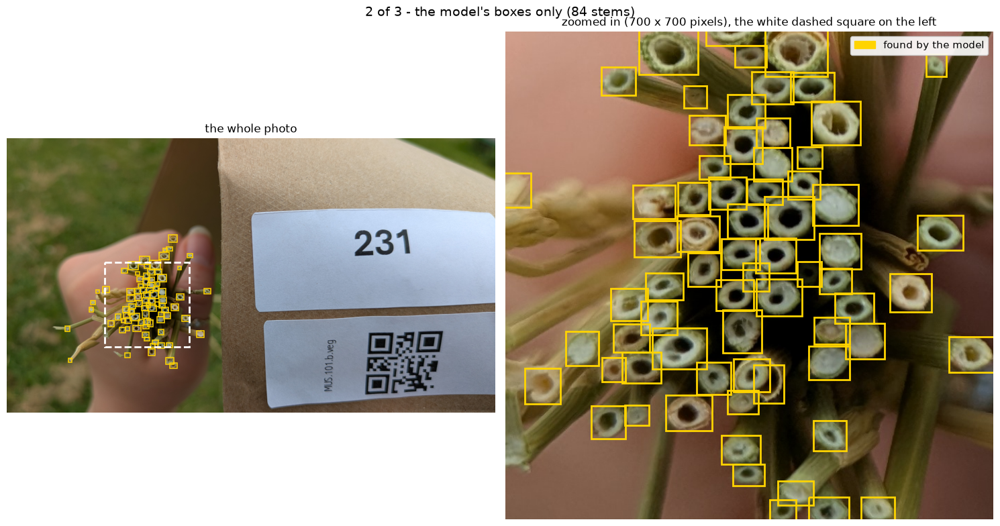

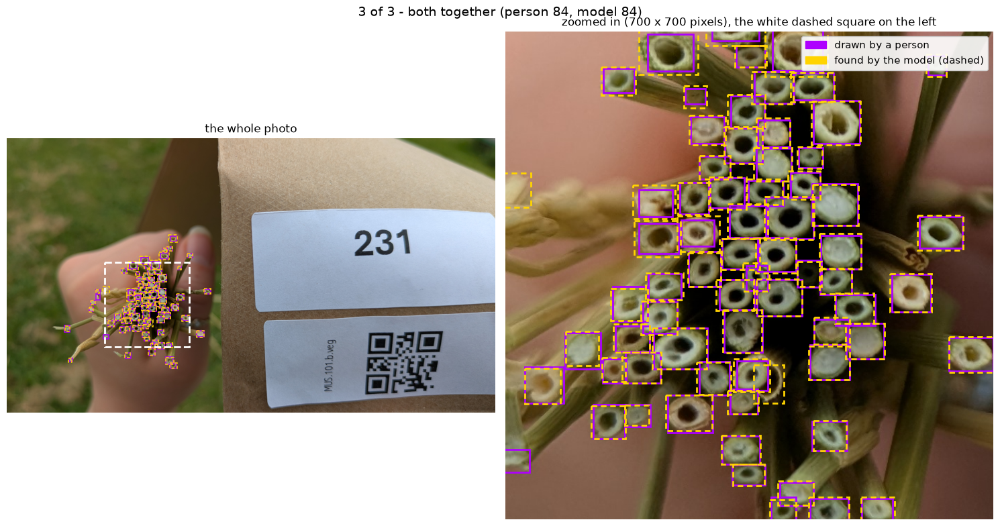

In [22]:
# Use the same zoom window in all three, so they can be compared directly.
if len(truth_boxes):
    zoom_corner = (np.median(truth_boxes[:, 0] + truth_boxes[:, 2] / 2) - 350,
                   np.median(truth_boxes[:, 1] + truth_boxes[:, 3] / 2) - 350)
else:
    zoom_corner = None

show(photo_array,
     [(truth_boxes, COLOR_TRUTH, "drawn by a person")],
     f"1 of 3 - hand-drawn boxes only ({len(truth_boxes)} stems)",
     zoom=zoom_corner)

show(photo_array,
     [(model_boxes_xywh, COLOR_PREDICTION, "found by the model")],
     f"2 of 3 - the model's boxes only ({len(model_boxes)} stems)",
     zoom=zoom_corner)

# In the overlay the model's boxes are DASHED. Where the model and the person
# agree the two boxes sit almost on top of each other, and a solid box would
# simply hide the one underneath it.
show(photo_array,
     [(truth_boxes, COLOR_TRUTH, "drawn by a person", "solid"),
      (model_boxes_xywh, COLOR_PREDICTION, "found by the model (dashed)", (0, (3, 2)))],
     f"3 of 3 - both together (person {len(truth_boxes)}, model {len(model_boxes)})",
     zoom=zoom_corner)

### How to read the overlay

In the zoomed panel, purple boxes are solid and the model's are dashed:

- **a solid purple box with a dashed yellow one on top** — the model agrees
  with the person. Most stems should look like this.
- **a solid purple box on its own** — the person marked a stem the model missed.
- **a dashed yellow box on its own** — the model found something the person did
  not mark. Sometimes that is a genuine mistake by the model; sometimes it is a
  stem the annotator missed.

Note that the two boxes around an agreed stem will not sit exactly on top of
each other, and that is expected. What matters for a count is that there is one
box per stem, not that the edges line up to the pixel.

Eyeballing one photo tells you whether the pipeline is working. It does not
tell you how accurate the model is — for that you need all 50 test photos and
proper matching between marked and found boxes, which is what the paper
reports.

---
## What now

- **Look at a different photo.** Go back to step 1, change `IMAGE_INDEX`, and
  run the cells from there down. Try a few — the interesting ones are the
  photos where stems overlap or the lighting is poor.
- **Count a whole folder of photos.** That is the companion notebook,
  `02_count_a_whole_folder.ipynb`. It writes a spreadsheet of counts and reads
  the QR code label in each photo.

### If something went wrong

| what you saw | what it usually means |
|---|---|
| `FileNotFoundError` in step 1 | The paths in the settings cell do not match where the notebook is running. The error message prints the folder it is looking in. |
| `NameError: 'model' is not defined` | A cell was skipped. Run the cells in order from the top. |
| Boxes drawn in odd places | The corner-plus-size and two-corners conventions got mixed up, or the rotation fix in step 3 was skipped. |
| Boxes outside the photo (step 3 warns) | The annotations were made before the rotation fix was applied. |
| Everything is very slow | No graphics card. If you have access to a more powerful computer, try using that. Otherwise, you may just have to be patient. |

### The settings, and why they are what they are

`CONFIDENCE = 0.45` was not picked by eye. It was chosen on a **separate
validation set** of photos — never the test photos — as the threshold at which
the model's counts stop being systematically too low or too high. Lower it and
the model finds more stems but starts inventing them; raise it and it misses
real ones. Choosing it on separate photos is what makes the reported accuracy
an honest estimate rather than a best case.